In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

data = pd.read_csv("noisy_curvefit_data.csv")
print(data)
print(data.shape)

           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0  -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1  -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2  -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3  -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4  -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113
..       ...        ...        ...        ...        ...        ...
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850

[100 rows x 6 columns]
(100, 6)


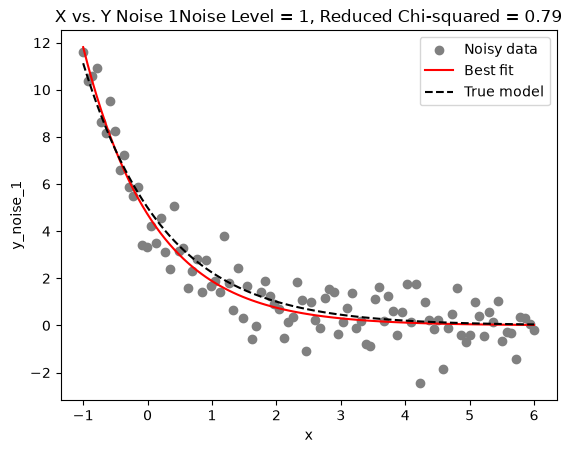

In [23]:
plt.scatter(data["x"], data["y_noise_1"], color="gray", label="Noisy data")

plt.xlabel("x")
plt.ylabel("y_noise_1")

def model(x, A, k):
    return A * np.exp(-k * x)
   
x = data["x"]
y_noise_1 = data["y_noise_1"]

p0 = [1, 1]

popt, pcov = curve_fit(model, x, y_noise_1, p0=p0)

A_fit, k_fit = popt

y_fit = model(x, A_fit, k_fit)

residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2 / dof

plt.plot(x, y_fit, color="red", label="Best fit")
plt.plot(x, model(x, 5, 0.8), color="black", linestyle="--", label="True model")
plt.title("X vs. Y Noise 1" f"Noise Level = 1, Reduced Chi-squared = {chi2_reduced:.2f}")
plt.legend()
plt.show()


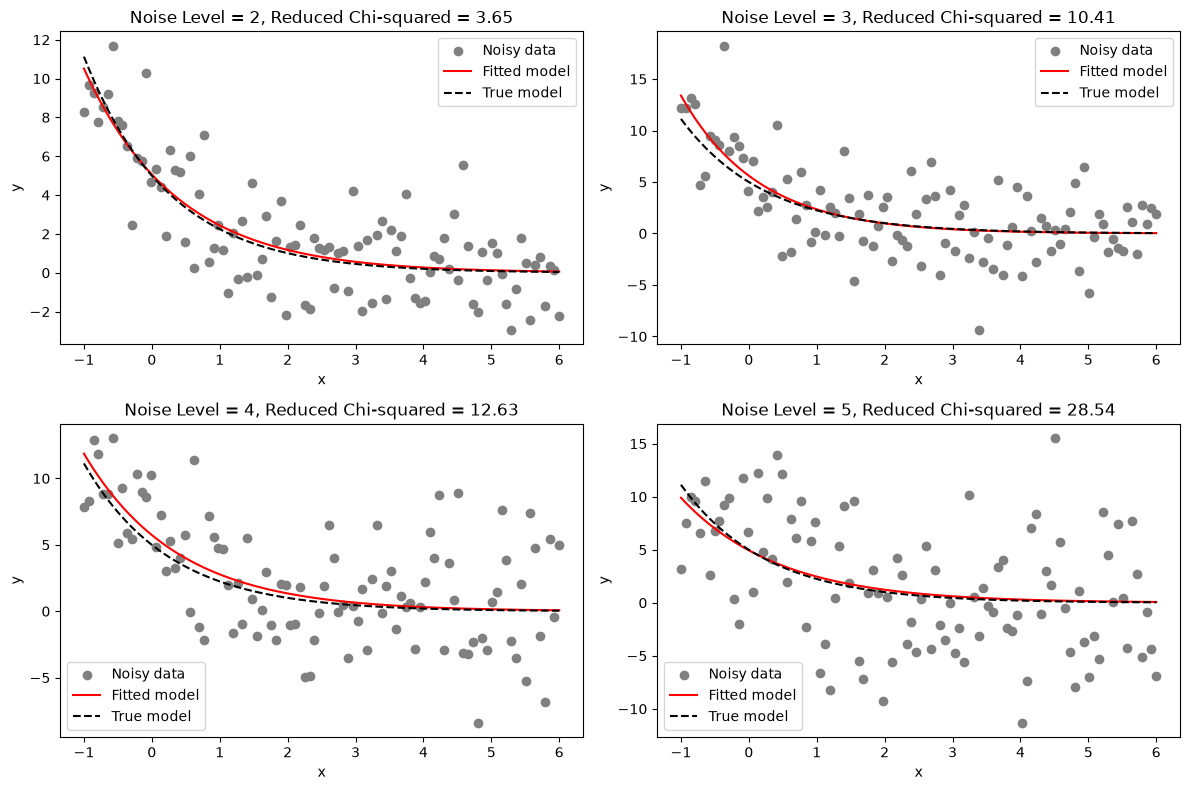

In [26]:
def fit_model(x, y):
    p0 = [1, 1]
    popt, pcov = curve_fit(model, x, y, p0=p0)
    residuals = y - model(x, *popt)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    return popt, chi2_reduced

y_data = [data["y_noise_2"], data["y_noise_3"],
          data["y_noise_4"], data["y_noise_5"]]


noise_levels = [2, 3, 4, 5]


fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, y, noise in zip(axes.flat, y_data, noise_levels):

    popt, chi2_reduced = fit_model(x, y)


    ax.scatter(x, y, color="gray", label="Noisy data")

  
    ax.plot(x, model(x, *popt), color="red", label="Fitted model")

 
    ax.plot(x, model(x, 5, 0.8), color="black",
            linestyle="--", label="True model")

    ax.set_title(f"Noise Level = {noise}, Reduced Chi-squared = {chi2_reduced:.2f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()

plt.tight_layout()
plt.show()

In [29]:
#red line is less accurate bc noise levels deviate further from an average
#black line is true model so stays the same
#chi squared increase bc the noise deviation becomes larger

y_data = [data["y_noise_1"], data["y_noise_2"],
          data["y_noise_3"], data["y_noise_4"],
          data["y_noise_5"]]

noise_levels = [1, 2, 3, 4, 5]

A_fits = []
k_fits = []
chi2_values = []

for y in y_data:
    popt, chi2_reduced = fit_model(x, y)

    A_fit, k_fit = popt

    A_fits.append(A_fit)
    k_fits.append(k_fit)
    chi2_values.append(chi2_reduced)

df = pd.DataFrame({
    "Noise level": noise_levels,
    "A fit": A_fits,
    "k fit": k_fits,
    "Reduced chi-squared": chi2_values
})

df

,Noise level,A fit,k fit,Reduced chi-squared
0,1,4.714814,0.918308,0.790673
1,2,5.063889,0.730396,3.649382
2,3,5.609396,0.870372,10.410207
3,4,5.738727,0.725965,12.626832
4,5,4.943458,0.695012,28.538124


In [30]:
df.to_csv("noisy_parameters.csv", index=False)